# Gênero musical, rótulos múltiplos e modelo nulo — MTG-Jamendo

Este notebook reproduz toda a análise do trabalho:

1. **Leitura** do arquivo de gêneros do MTG-Jamendo (`autotagging_genre.tsv`).
2. **Contagem** de quantos gêneros distintos cada faixa tem (*k*).
3. **Modelo nulo:** concordância esperada entre duas escolhas aleatórias de um único gênero, `1/k` por faixa e a média no dataset.
4. **Verificação por Monte Carlo** (50 e 100 rodadas).
5. **Métrica antiga** (instabilidade sob reordenação) e por que ela foi substituída.
6. **Figura** e **arquivos de resultado** (identificação das faixas mono e multirrótulo).

Roda no Google Colab ou no Jupyter, sem GPU, em poucos segundos.

In [1]:
import os, csv, urllib.request
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

URL = "https://raw.githubusercontent.com/MTG/mtg-jamendo-dataset/master/data/autotagging_genre.tsv"
ARQ = "autotagging_genre.tsv"
os.makedirs("resultados", exist_ok=True)
os.makedirs("figuras", exist_ok=True)

if not os.path.exists(ARQ):
    urllib.request.urlretrieve(URL, ARQ)
print("Arquivo pronto:", ARQ)

Arquivo pronto: autotagging_genre.tsv


## 1. Leitura dos dados

O arquivo tem largura variável: as 5 primeiras colunas são fixas (`TRACK_ID`, `ARTIST_ID`, `ALBUM_ID`, `PATH`, `DURATION`) e, a partir da 6ª, vem uma tag por coluna no formato `genre---nome`. Por isso a leitura é feita linha a linha.

In [2]:
linhas = []
with open(ARQ, encoding="utf-8") as f:
    leitor = csv.reader(f, delimiter="\t")
    next(leitor)  # cabeçalho
    for row in leitor:
        if not row:
            continue
        generos = sorted({t.split("---", 1)[1] for t in row[5:] if t.startswith("genre---")})
        if generos:
            linhas.append({"track_id": row[0], "artist_id": row[1], "album_id": row[2],
                           "generos": generos, "k": len(generos)})

df = pd.DataFrame(linhas)
todas_tags = sorted({g for gs in df["generos"] for g in gs})
print(f"Faixas com gênero: {len(df):,}".replace(",", "."))
print(f"Tags de gênero distintas: {len(todas_tags)}")
df.head()

Faixas com gênero: 55.215
Tags de gênero distintas: 95


,track_id,artist_id,album_id,generos,k
0,track_0000214,artist_000014,album_000031,[punkrock],1
1,track_0000215,artist_000014,album_000031,[metal],1
2,track_0000216,artist_000014,album_000031,[metal],1
3,track_0000217,artist_000014,album_000031,[punkrock],1
4,track_0000218,artist_000014,album_000031,[punkrock],1


## 2. Contagem de gêneros por faixa (*k*)

*k* é o número de gêneros **distintos** atribuídos a uma faixa. Uma faixa é **multirrótulo** quando *k* > 1.

In [3]:
N = len(df)
df["multirrotulo"] = df["k"] > 1
N_multi = int(df["multirrotulo"].sum())

dist = df["k"].value_counts().sort_index().rename("faixas").to_frame()
dist["porcentagem"] = 100 * dist["faixas"] / N
dist["concordancia_1_k"] = 1 / dist.index
print(f"Faixas multirrótulo: {N_multi:,} de {N:,} = {100 * N_multi / N:.1f}%".replace(",", "."))
print(f"Média de k entre as multirrótulo: {df.loc[df.multirrotulo, 'k'].mean():.2f}")
dist.round(3)

Faixas multirrótulo: 43.494 de 55.215 = 78.8%
Média de k entre as multirrótulo: 2.85


,faixas,porcentagem,concordancia_1_k
k,,,
1,11721,21.228,1.000
2,16388,29.680,0.500
3,20087,36.380,0.333
4,4704,8.519,0.250
5,1798,3.256,0.200
6,390,0.706,0.167
7,110,0.199,0.143
8,7,0.013,0.125
9,10,0.018,0.111


## 3. Modelo nulo: concordância esperada

Se dois observadores escolhem, de forma independente e com a mesma chance para cada gênero, um dos *k* gêneros de uma faixa, a probabilidade de escolherem o mesmo é:

$$P(\text{concordância} \mid k) = \frac{1}{k}$$

Para *N* faixas, a concordância esperada é a média:

$$\mathbb{E}[\text{concordância}] = \frac{1}{N}\sum_{i=1}^{N} \frac{1}{k_i}$$

Se os dois compartilham uma preferência $p = (p_1, \dots, p_k)$, a concordância passa a $\sum_j p_j^2 \geq 1/k$: o caso uniforme é o de **menor** concordância.

In [4]:
inv_k = 1 / df["k"]
conc_todas = inv_k.mean()
conc_multi = inv_k[df.multirrotulo].mean()
contrib_mono = (~df.multirrotulo).sum() / N  # faixas com k = 1 sempre concordam

print(f"Concordância esperada (todas as faixas): {100 * conc_todas:.1f}%")
print(f"Concordância esperada (só multirrótulo): {100 * conc_multi:.1f}%")
print(f"Discordância esperada (só multirrótulo): {100 * (1 - conc_multi):.1f}%")
print(f"Contribuição das faixas com k = 1: {100 * contrib_mono:.1f} pontos percentuais")

Concordância esperada (todas as faixas): 51.1%
Concordância esperada (só multirrótulo): 38.0%
Discordância esperada (só multirrótulo): 62.0%
Contribuição das faixas com k = 1: 21.2 pontos percentuais


## 4. Verificação por Monte Carlo

Simulação direta do modelo: em cada rodada, para cada faixa, sorteiam-se **dois** gêneros da sua lista, de forma independente e uniforme; conta-se 1 quando coincidem. A média de todas as rodadas estima a concordância e deve coincidir com a fórmula exata.

In [5]:
rng = np.random.default_rng(42)
k_arr = df["k"].to_numpy()
multi_mask = df["multirrotulo"].to_numpy()

mc = []
for R in (50, 100):
    acertos = np.zeros(N)
    for _ in range(R):
        a = rng.integers(0, k_arr)
        b = rng.integers(0, k_arr)
        acertos += (a == b)
    taxa = acertos / R
    mc.append({"rodadas": R,
               "concordancia_todas_simulada": taxa.mean(),
               "concordancia_multi_simulada": taxa[multi_mask].mean(),
               "concordancia_todas_formula": conc_todas,
               "concordancia_multi_formula": conc_multi})
mc = pd.DataFrame(mc)
(mc.set_index("rodadas") * 100).round(2)

,concordancia_todas_simulada,concordancia_multi_simulada,concordancia_todas_formula,concordancia_multi_formula
rodadas,,,,
50,51.16,38.00,51.13,37.95
100,51.14,37.98,51.13,37.95


## 5. A métrica antiga e por que ela foi substituída

A primeira versão do trabalho reordenava aleatoriamente a lista de gêneros de cada faixa *R* vezes e tomava o primeiro item como rótulo único; a faixa era **instável** se o rótulo mudasse em alguma rodada.

Uma faixa com *k* gêneros só é estável se o mesmo gênero sair nas *R* rodadas, com probabilidade $k \cdot (1/k)^R = k^{1-R}$. Com mais rodadas, quase toda faixa multirrótulo fica instável, e a instabilidade **converge para a proporção de faixas multirrótulo** (78,8%): a métrica era consequência mecânica dessa proporção, e não um achado independente.

In [6]:
inst = []
for R in (5, 50, 100):
    escolhas = rng.integers(0, k_arr, size=(R, N))
    instavel = (escolhas != escolhas[0]).any(axis=0)
    inst.append({"rodadas": R,
                 "instaveis_simulado_%": 100 * instavel.mean(),
                 "instaveis_esperado_%": 100 * (1 - (k_arr ** (1.0 - R))).mean(),
                 "proporcao_multirrotulo_%": 100 * multi_mask.mean()})
inst = pd.DataFrame(inst)
inst.round(2)

,rodadas,instaveis_simulado_%,instaveis_esperado_%,proporcao_multirrotulo_%
0,5,76.45,76.43,78.77
1,50,78.77,78.77,78.77
2,100,78.77,78.77,78.77


## 6. Figura: distribuição de *k* e concordância 1/*k*

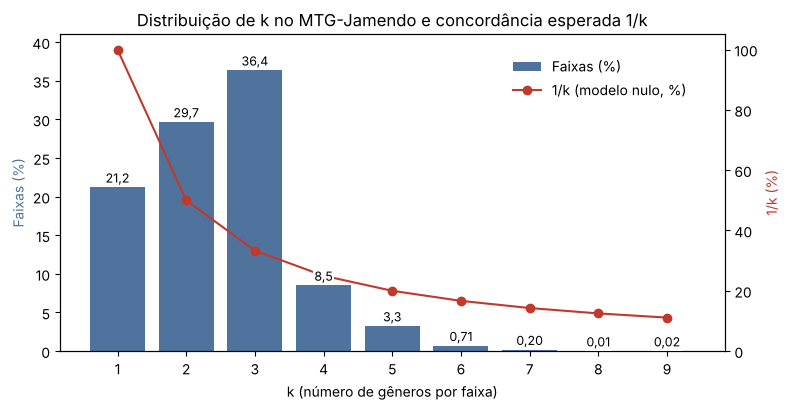

In [7]:
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.bar(dist.index, dist["porcentagem"], color="#50739E", label="Faixas (%)")
ax.set_xlabel("k (número de gêneros por faixa)")
ax.set_ylabel("Faixas (%)", color="#50739E")
ax.set_xticks(dist.index)
ax2 = ax.twinx()
ax2.plot(dist.index, 100 / dist.index, color="#C0392B", marker="o", label="1/k (modelo nulo, %)")
ax2.set_ylabel("1/k (%)", color="#C0392B")
ax2.set_ylim(0, 105)
ax.set_ylim(0, 41)
for x, v in zip(dist.index, dist["porcentagem"]):
    ax2.text(x, v + 0.6, f"{v:.1f}".replace(".", ",") if v >= 1 else f"{v:.2f}".replace(".", ","),
            ha="center", fontsize=9, zorder=5, transform=ax.transData,
            bbox=dict(facecolor="white", edgecolor="none", pad=1))
ax.set_title("Distribuição de k no MTG-Jamendo e concordância esperada 1/k")
fig.legend(loc="upper right", bbox_to_anchor=(0.88, 0.88), frameon=False)
fig.tight_layout()
fig.savefig("figuras/distribuicao_k_1k.png", dpi=200)
fig.savefig("figuras/distribuicao_k_1k.pdf")
plt.show()

## 7. Arquivos disponibilizados

- `resultados/faixas_mono_multi.csv`: cada faixa com seu *k*, seus gêneros e a marcação mono/multirrótulo. Permite avaliar classificadores e recomendadores separadamente em cada subconjunto.
- `resultados/distribuicao_k.csv`: quantas faixas têm cada valor de *k*.
- `resultados/resumo.csv`: os números principais.
- `resultados/monte_carlo.csv` e `resultados/metrica_antiga.csv`: as verificações por simulação.

In [8]:
saida = df.assign(generos=df["generos"].str.join("|"))[
    ["track_id", "artist_id", "album_id", "k", "multirrotulo", "generos"]]
saida.to_csv("resultados/faixas_mono_multi.csv", index=False)

dist.rename_axis("k").to_csv("resultados/distribuicao_k.csv")

resumo = pd.DataFrame([
    ("faixas_com_genero", N),
    ("tags_de_genero", len(todas_tags)),
    ("faixas_multirrotulo", N_multi),
    ("proporcao_multirrotulo_%", round(100 * N_multi / N, 1)),
    ("media_k_multirrotulo", round(df.loc[df.multirrotulo, "k"].mean(), 2)),
    ("concordancia_esperada_todas_%", round(100 * conc_todas, 1)),
    ("concordancia_esperada_multi_%", round(100 * conc_multi, 1)),
    ("contribuicao_mono_pp", round(100 * contrib_mono, 1)),
], columns=["metrica", "valor"], dtype=object)
resumo.to_csv("resultados/resumo.csv", index=False)
mc.to_csv("resultados/monte_carlo.csv", index=False)
inst.to_csv("resultados/metrica_antiga.csv", index=False)
resumo

,metrica,valor
0,faixas_com_genero,55215
1,tags_de_genero,95
2,faixas_multirrotulo,43494
3,proporcao_multirrotulo_%,78.8
4,media_k_multirrotulo,2.85
5,concordancia_esperada_todas_%,51.1
6,concordancia_esperada_multi_%,38.0
7,contribuicao_mono_pp,21.2
